In [1]:
import simulation
import HminLower
import shannonLower
import matplotlib.pyplot as plt
import numpy as np
import ShannonGEAT


# Time bin encoding

## Ideal

In [2]:
res = {'shannon': [], 'hmin': [], 'deltas': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '1')
    hmin = HminLower.getHmin(p, delta, 1/2)
    shannon = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)

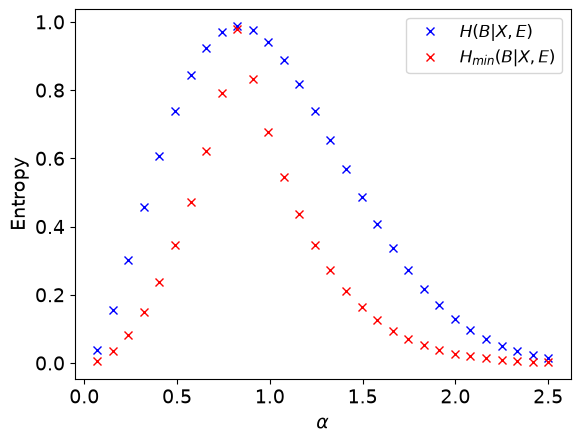

In [3]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin'], 'rx', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

In [4]:
alphas[res['shannon'].index(max(res['shannon']))]

np.float64(0.8241379310344827)

## Bad detector

In [5]:
res = {'shannon': [], 'hmin': [], 'deltas': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 0.7, 1e-6, '1', True)
    hmin = HminLower.getHmin(p, delta, 1/2)
    shannon = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)

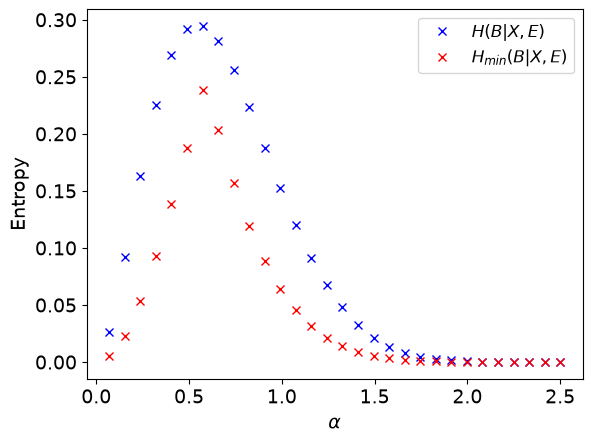

In [6]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin'], 'rx', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

In [7]:
alphas[res['shannon'].index(max(res['shannon']))]

np.float64(0.5727586206896553)

## Difference between $c$ and $b$ variables

In [8]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': [], 'diffhmin': [], 'diffh': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 0.7, 1e-6, '1', True)
    hmin = HminLower.getHmin(p, delta, 1/2, True)
    shannon = shannonLower.runOpti(delta, p, 1/2)
    hmin2 = HminLower.getHmin(p, delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p, 1/2, 2)
    diffhmin = np.abs(hmin-hmin2)
    diffh = np.abs(shannon-shannon2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)
    res['diffhmin'].append(diffhmin)
    res['diffh'].append(diffh)

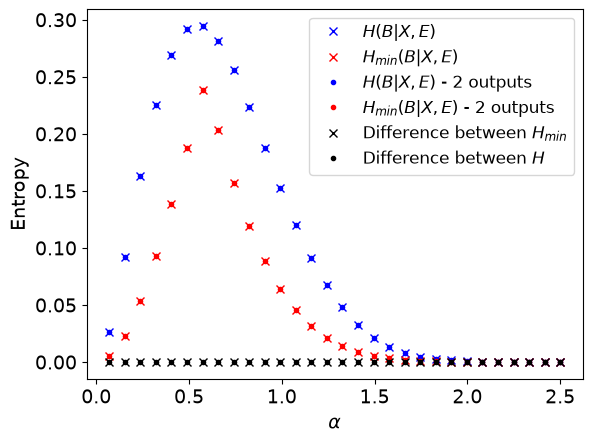

In [9]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin'], 'rx', label=r'$H_{min}(B|X,E)$')
plt.plot(alphas, res['shannon2'], 'b.', label=r'$H(B|X,E)$ - 2 outputs')
plt.plot(alphas, res['hmin2'], 'r.', label=r'$H_{min}(B|X,E)$ - 2 outputs')
plt.plot(alphas, res['diffhmin'], 'kx', label=r'Difference between $H_{min}$')
plt.plot(alphas, res['diffh'], 'k.', label=r'Difference between $H$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

## Bad Detector and source

In [10]:
res = {'shannon': [], 'hmin': [], 'deltas': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    amax, delta, p = simulation.doSimul(alpha, 1/2, '1', 100000, 0.7, True, True)
    hmin = HminLower.getHmin(p[0], delta, 1/2, True)
    shannon = shannonLower.runOpti(delta, p[0], 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)

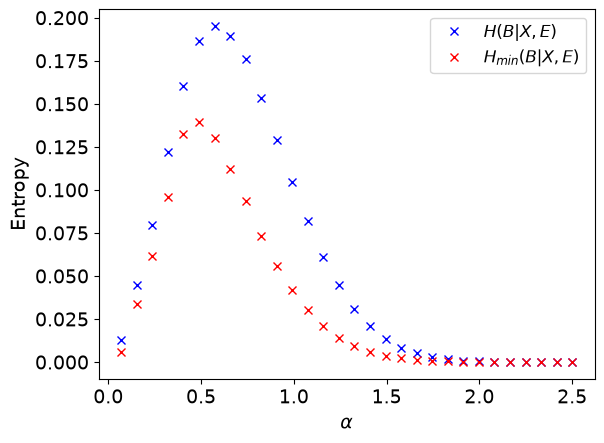

In [11]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin'], 'rx', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

In [12]:
alphas[res['shannon'].index(max(res['shannon']))]

np.float64(0.5727586206896553)

## Block size study

In [13]:
alpha = alphas[res['shannon'].index(max(res['shannon']))]
npoints = np.linspace(3, 7, 10)

amax, delta, p = simulation.doSimul(alpha, 1/2, '1', 100000, 0.7, True, True)
H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)

In [14]:
vals = []
for npoint in npoints:
    ps = []
    delta = 0.0
    for i in range(5):
        amax, delta, p = simulation.doSimul(alpha, 1/2, '1', int(10**npoint), 0.7, True, True)
        ps.append(p[0])
    val3 = ShannonGEAT.getH3(ps, int(10**npoint), lambdas, Rs, cm)
    vals.append(val3)
    

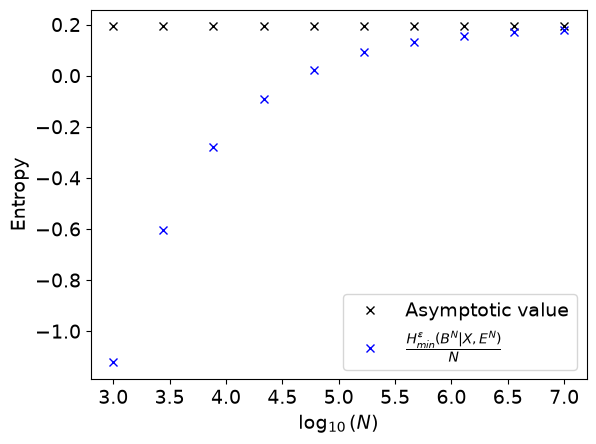

In [15]:
plt.figure()
Hts = [H_theo]*10
plt.plot(npoints, Hts, 'kx', label=r'Asymptotic value')
plt.plot(npoints, vals, 'bx', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r"$\log_{10}(N)$", fontsize=14)
plt.ylabel(r"Entropy", fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)

## Bad detector, source + finite size

In [16]:
res = {'alpha': [], 'vals': [], }
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    ps = []
    delta = 0.0
    amax, delta, p = simulation.doSimul(alpha, 1/2, '1', 100000, 0.7, True, True)
    H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)
    for i in range(5):
        amax, delta, p = simulation.doSimul(alpha, 1/2, '1', 100000, 0.7, True, True)
        ps.append(p[0])
    val = ShannonGEAT.getH3(ps, 100000, lambdas, Rs, cm)
    res['vals'].append(val)
    res['alpha'].append(alpha)

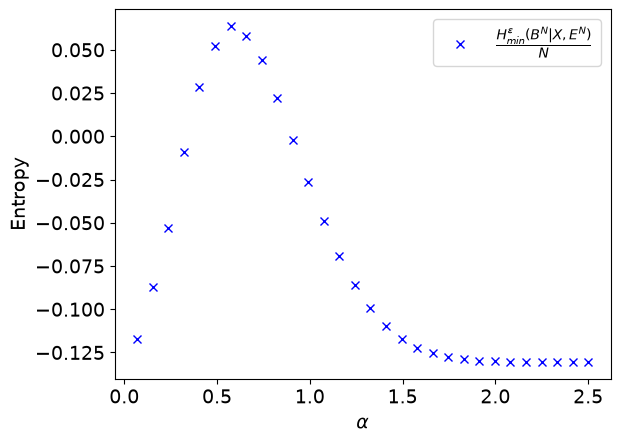

In [17]:
plt.figure()
plt.plot(alphas, res['vals'], 'bx', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)

In [18]:
alphas[res['vals'].index(max(res['vals']))]

np.float64(0.5727586206896553)

# Photon number

## Ideal

In [19]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '0')
    hmin = HminLower.getHmin(p, delta, 7/8)
    shannon = shannonLower.runOpti(delta, p, 7/8)
    hmin2 = HminLower.getHmin(p, delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

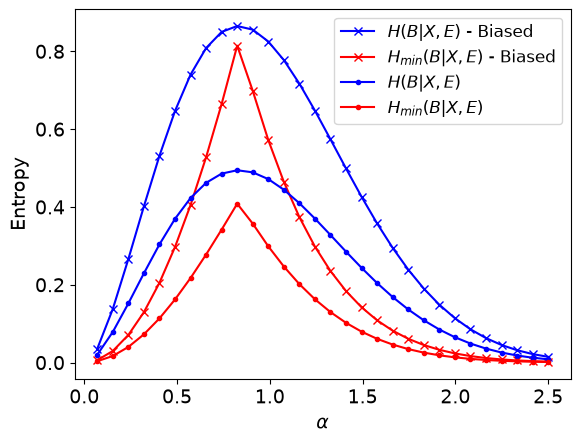

In [20]:
plt.figure()
plt.plot(alphas, res['shannon'], 'b-x', label=r'$H(B|X,E)$ - Biased')
plt.plot(alphas, res['hmin'], 'r-x', label=r'$H_{min}(B|X,E)$ - Biased')
plt.plot(alphas, res['shannon2'], 'b.-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin2'], 'r.-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "PerfNumber.pdf",
    bbox_inches="tight"
)

## Bad detector

In [21]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 0.7, 1e-6, '0', True)
    hmin = HminLower.getHmin(p, delta, 7/8)
    shannon = shannonLower.runOpti(delta, p, 7/8)
    hmin2 = HminLower.getHmin(p, delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

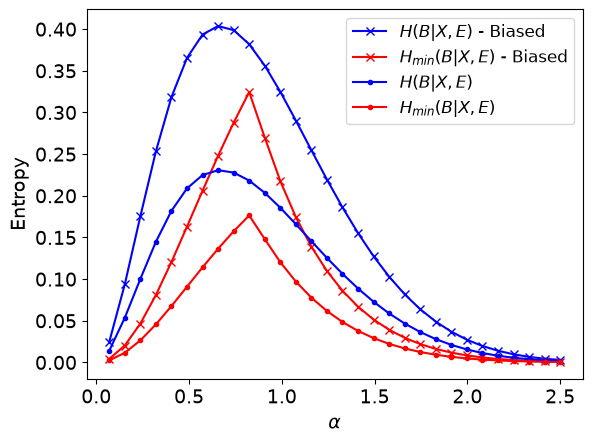

In [22]:
plt.figure()
plt.plot(alphas, res['shannon'], 'b-x', label=r'$H(B|X,E)$ - Biased')
plt.plot(alphas, res['hmin'], 'r-x', label=r'$H_{min}(B|X,E)$ - Biased')
plt.plot(alphas, res['shannon2'], 'b.-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin2'], 'r.-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "DetectorNumber.pdf",
    bbox_inches="tight"
)

## Bad detector and source

In [24]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    amax, delta, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
    hmin = HminLower.getHmin(p[0], delta, 7/8)
    shannon = shannonLower.runOpti(delta, p[0], 7/8)
    amax, delta, p = simulation.doSimul(alpha, 1/2, '0', 100000, 0.7, True, True)
    hmin2 = HminLower.getHmin(p[0], delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p[0], 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

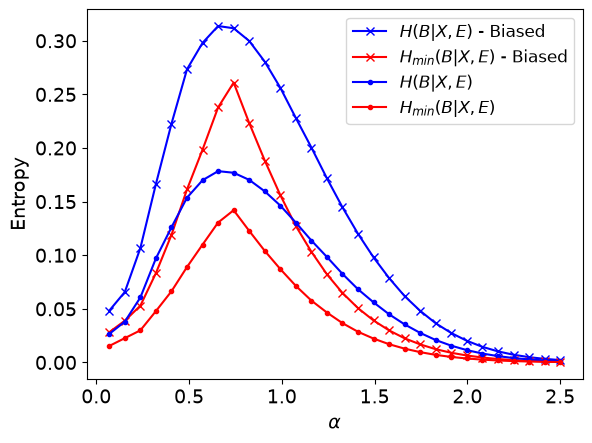

In [25]:
plt.figure()
plt.plot(alphas, res['shannon'], 'b-x', label=r'$H(B|X,E)$ - Biased')
plt.plot(alphas, res['hmin'], 'r-x', label=r'$H_{min}(B|X,E)$ - Biased')
plt.plot(alphas, res['shannon2'], 'b.-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin2'], 'r.-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "BadSourceNumber.pdf",
    bbox_inches="tight"
)

## Blocksize study

In [26]:
alpha = 0.58
npoints = np.linspace(3, 7, 10)

amax, delta, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)

In [27]:
vals = []
for npoint in npoints:
    ps = []
    delta = 0.0
    for i in range(5):
        amax, delta, p = simulation.doSimul(alpha, 7/8, '0', int(10**(npoint)), 0.7, True, True)
        ps.append(p[0])
    val3 = ShannonGEAT.getH3(ps, int(10**npoint), lambdas, Rs, cm)
    vals.append(val3)
    

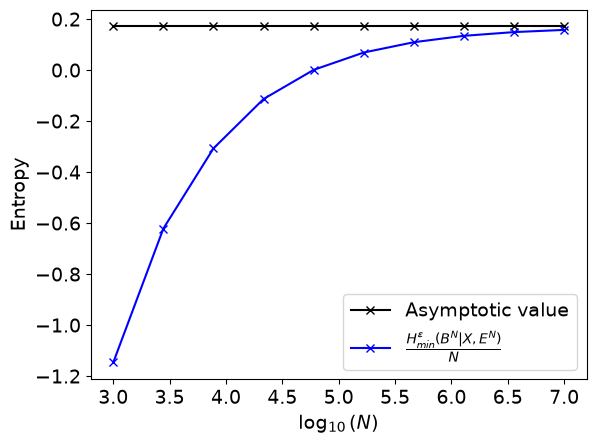

In [28]:
plt.figure()
Hts = [H_theo]*10
plt.plot(npoints, Hts, 'kx-', label=r'Asymptotic value')
plt.plot(npoints, vals, 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r"$\log_{10}(N)$", fontsize=14)
plt.ylabel(r"Entropy", fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "BlockSizeNumber.pdf",
    bbox_inches="tight"
)

## Bad detector, source + finite size

In [29]:
res = {'alpha': [], 'vals': [], 'vals2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    ps = []
    ps2 = []
    amax, delta, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
    amax, delta2, p2 = simulation.doSimul(alpha, 1/2, '0', 100000, 0.7, True, True)
    H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 7/8)
    H_theo2, lambdas2, Rs2, cm2 = shannonLower.getHDual(delta2, p2[0], 1/2)
    for i in range(5):
        amax, delta, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
        amax, delta2, p2 = simulation.doSimul(alpha, 1/2, '0', 100000, 0.7, True, True)
        ps.append(p[0])
        ps2.append(p2[0])
    val = ShannonGEAT.getH3(ps, 100000, lambdas, Rs, cm)
    val2 = ShannonGEAT.getH3(ps2, 100000, lambdas2, Rs2, cm2)
    res['vals'].append(val)
    res['vals2'].append(val2)
    res['alpha'].append(alpha)

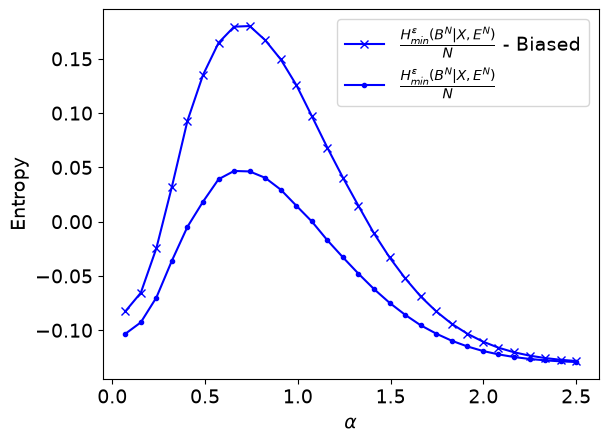

In [30]:
plt.figure()
plt.plot(alphas, res['vals'], 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$ - Biased')
plt.plot(alphas, res['vals2'], 'b.-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "FiniteSizeNumber.pdf",
    bbox_inches="tight"
)

In [31]:
alphas[res['vals'].index(max(res['vals']))]

np.float64(0.740344827586207)

# BPSK without inconclusive

## Ideal

In [32]:
res = {'shannon': [], 'hmin': [], 'deltas': []}
alphas = np.linspace(0, 2, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '2', False)
    hmin = HminLower.getHmin(p, delta, 1/2)
    shannon = shannonLower.runOpti(delta, p, 1/2, 2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)

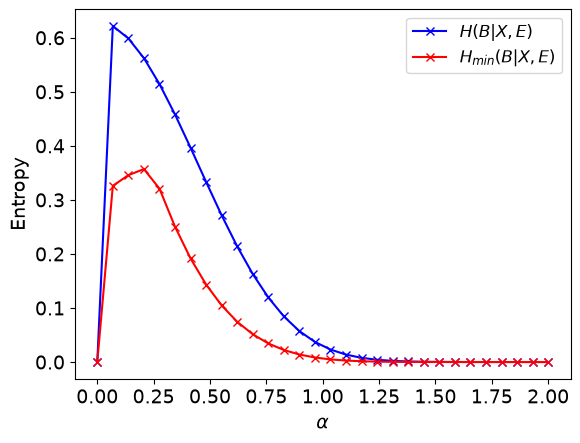

In [33]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin'], 'rx-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "PerfBPSK.pdf",
    bbox_inches="tight"
)

## P_noise

In [34]:
res = [{'deltas': [], 'shannon': [], 'hmin': []} for _ in range(4)]
alphas = np.linspace(0.07, 1.3, 20)
pnoises = np.linspace(0, 1, 4)

for i, pnoise in enumerate(pnoises):
    for alpha in alphas:
        delta, p = simulation.doSimul(alpha, 1/2, '2', 1000000, 1, False, False, 0, pnoise)
        hmin = HminLower.getHmin(p[0], delta, 1/2)
        shannon = shannonLower.runOpti(delta, p[0], 1/2, 2)
        res[i]['shannon'].append(shannon)
        res[i]['hmin'].append(hmin)
        res[i]['deltas'].append(delta)

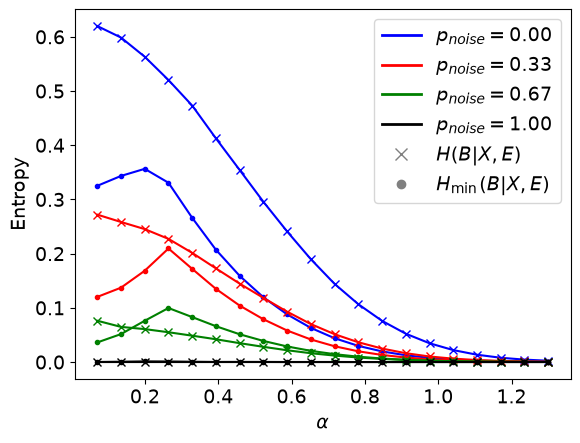

In [35]:
from matplotlib.lines import Line2D

plt.figure()

colors = ['b', 'r', 'g', 'k']

for i in range(4):
    plt.plot(alphas, res[i]['shannon'], colors[i] + 'x-')
    plt.plot(alphas, res[i]['hmin'], colors[i] + '.-')

plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel('Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# Legend for colors: p_noise
color_handles = [
    Line2D([0], [0], color=colors[i], lw=2,
           label=rf'$p_{{noise}} = {pnoises[i]:.2f}$')
    for i in range(4)
]

# Legend for markers: entropy type
marker_handles = [
    Line2D([0], [0], color='gray', marker='x', linestyle='None',
           markersize=8, label=r'$H(B|X,E)$'),
    Line2D([0], [0], color='gray', marker='.', linestyle='None',
           markersize=12, label=r'$H_{\min}(B|X,E)$')
]

plt.legend(handles=color_handles + marker_handles, fontsize=14)

plt.savefig("BadSourceBPSK.pdf", bbox_inches="tight")

## finite size

In [36]:
res = {'alpha': [], 'vals': []}
alphas = np.linspace(0.01, 2, 30)

for alpha in alphas:
    ps = []
    delta = 0.0
    delta, p = simulation.doSimul(alpha, 1/2, '2', 100000, 1, False, False, 0, 0.6)
    H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)
    for i in range(5):
        delta, p = simulation.doSimul(alpha, 1/2, '2', 100000, 1, False, False, 0, 0.6)
        ps.append(p[0])
    val = ShannonGEAT.getH3(ps, 100000, lambdas, Rs, cm, 2)
    res['vals'].append(val)
    res['alpha'].append(alpha)

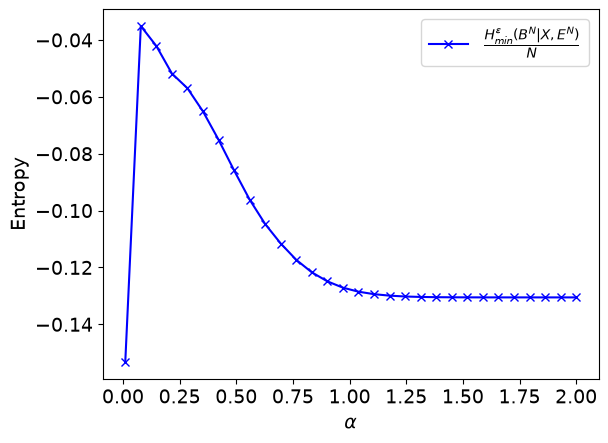

In [37]:
plt.figure()
plt.plot(alphas, res['vals'], 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "FiniteSizeBPSK2.pdf",
    bbox_inches="tight"
)

## Noise model + finite size

In [38]:
res = [{'alpha': [], 'vals': [], 'hmin': []} for _ in range(10)]
pnoises = np.linspace(0, 1, 4)
alphas = np.linspace(0.01, 1.2, 20)

for i, pnoise in enumerate(pnoises):
    for alpha in alphas:
        ps = []
        delta = 0.0
        delta, p = simulation.doSimul(alpha, 1/2, '2', 100000, 1, False, False, 0, pnoise)
        H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)
        hmin = HminLower.getHmin(p[0], delta, 1/2)
        for _ in range(5):
            delta, p = simulation.doSimul(alpha, 1/2, '2', 100000, 1, False, False, 0, pnoise)
            ps.append(p[0])
        val = ShannonGEAT.getH3(ps, 100000, lambdas, Rs, cm, 2)
        # print(val)
        res[i]['vals'].append(val)
        res[i]['alpha'].append(alpha)
        res[i]['hmin'].append(hmin)
        # print(res[i])

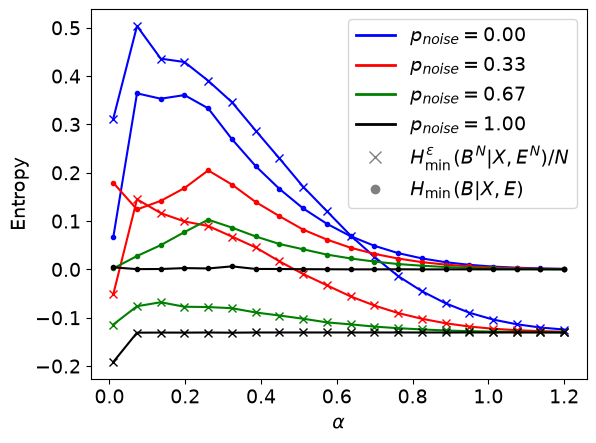

In [39]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.figure()

colors = ['b', 'r', 'g', 'k']

for i in range(4):
    plt.plot(alphas, res[i]['vals'], colors[i] + 'x-')
    plt.plot(alphas, res[i]['hmin'], colors[i] + '.-')

plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel('Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# Legend for colors: p_noise
color_handles = [
    Line2D([0], [0], color=colors[i], lw=2,
           label=rf'$p_{{noise}} = {pnoises[i]:.2f}$')
    for i in range(4)
]

# Legend for markers: entropy type
marker_handles = [
    Line2D([0], [0], color='gray', marker='x', linestyle='None',
           markersize=8, label=r'$H_{\min}^{\epsilon}(B^N|X,E^N)/N$'),
    Line2D([0], [0], color='gray', marker='.', linestyle='None',
           markersize=12, label=r'$H_{\min}(B|X,E)$')
]

plt.legend(handles=color_handles + marker_handles, fontsize=14)

plt.savefig("FiniteSizeBPSK.pdf", bbox_inches="tight")

# BPSK with inconclusive


## Ideal

In [40]:
res = {'shannon': [], 'shannon2': [], 'hmin': [], 'hmin2': [], 'deltas': []}
alphas = np.linspace(0, 2, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '3', False, np.sqrt(2)*alpha)
    hmin = HminLower.getHmin(p, delta, 1/2, True)
    hmin2 = HminLower.getHmin(p, delta, 1/2)
    shannon = shannonLower.runOpti(delta, p, 1/2)
    shannon2 = shannonLower.runOpti(delta, p, 1/2, 2)
    res['shannon'].append(shannon)
    res['shannon2'].append(shannon2)
    res['hmin'].append(hmin)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

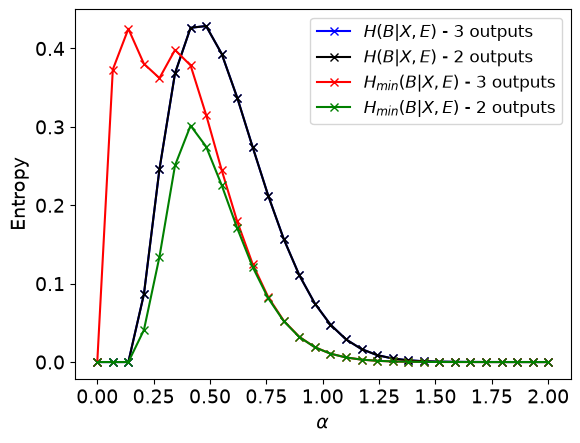

In [41]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx-', label=r'$H(B|X,E)$ - 3 outputs')
plt.plot(alphas, res['shannon2'], 'kx-', label=r'$H(B|X,E)$ - 2 outputs')
plt.plot(alphas, res['hmin'], 'rx-', label=r'$H_{min}(B|X,E)$ - 3 outputs')
plt.plot(alphas, res['hmin2'], 'gx-', label=r'$H_{min}(B|X,E)$ - 2 outputs')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "PerfBPSK3.pdf",
    bbox_inches="tight"
)

In [42]:
alphas[res['shannon'].index(max(res['shannon']))], alphas[res['shannon2'].index(max(res['shannon2']))]

(np.float64(0.48275862068965514), np.float64(0.48275862068965514))

## Bad alpha

In [43]:
res = {'shannon': [], 'shannon2': [], 'hmin': [], 'hmin2': [], 'deltas': []}
alphas = np.linspace(0.01, 2, 30)

for alpha in alphas:
    amax, delta, p = simulation.doSimul(alpha, 1/2, '3', 100000, 1, False, True, np.sqrt(2)*alpha)
    hmin = HminLower.getHmin(p[0], delta, 1/2, True)
    hmin2 = HminLower.getHmin(p[0], delta, 1/2)
    shannon = shannonLower.runOpti(delta, p[0], 1/2)
    shannon2 = shannonLower.runOpti(delta, p[0], 1/2, 2)
    res['shannon'].append(shannon)
    res['shannon2'].append(shannon2)
    res['hmin'].append(hmin)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

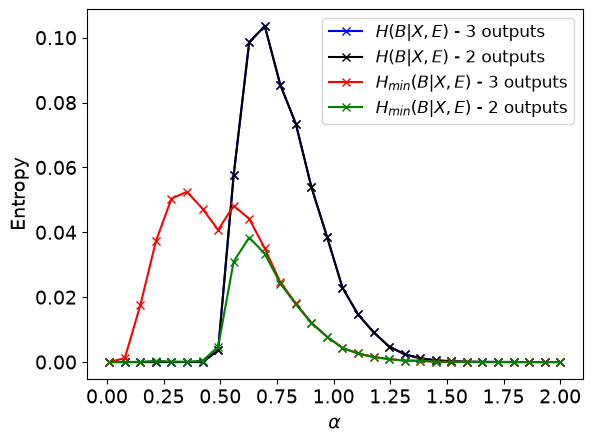

In [44]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx-', label=r'$H(B|X,E)$ - 3 outputs')
plt.plot(alphas, res['shannon2'], 'kx-', label=r'$H(B|X,E)$ - 2 outputs')
plt.plot(alphas, res['hmin'], 'rx-', label=r'$H_{min}(B|X,E)$ - 3 outputs')
plt.plot(alphas, res['hmin2'], 'gx-', label=r'$H_{min}(B|X,E)$ - 2 outputs')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "BadSourceBPSK3.pdf",
    bbox_inches="tight"
)

In [45]:
alphas[res['shannon'].index(max(res['shannon']))], alphas[res['shannon2'].index(max(res['shannon2']))]

(np.float64(0.6962068965517242), np.float64(0.6962068965517242))

## Blocksize

In [46]:
alpha = alphas[res['shannon'].index(max(res['shannon']))]
npoints = np.linspace(3, 7, 10)

amax, delta, p = simulation.doSimul(alpha, 1/2, '3', 1000000, 1, False, True, np.sqrt(2)*alpha)
H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)

In [47]:
vals = []
for npoint in npoints:
    ps = []
    delta = 0.0
    for i in range(5):
        amax, delta, p = simulation.doSimul(alpha, 1/2, '3', int(10**(npoint)), 1, False, True, np.sqrt(2)*alpha)
        ps.append(p[0])
    val3 = ShannonGEAT.getH3(ps, int(10**npoint), lambdas, Rs, cm)
    vals.append(val3)

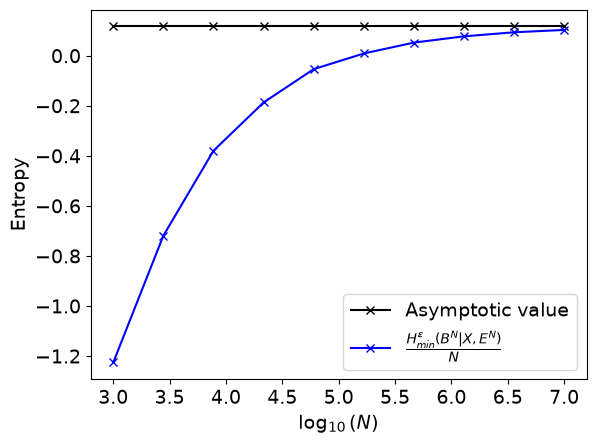

In [48]:
plt.figure()
Hts = [H_theo]*10
plt.plot(npoints, Hts, 'kx-', label=r'Asymptotic value')
plt.plot(npoints, vals, 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r"$\log_{10}(N)$", fontsize=14)
plt.ylabel(r"Entropy", fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "BlockSizeBPSK3.pdf",
    bbox_inches="tight"
)

## Bad alpha + finite size

In [49]:
res = {'alpha': [], 'vals': [], }
alphas = np.linspace(0.01, 2, 30)

for alpha in alphas:
    ps = []
    delta = 0.0
    amax, delta, p = simulation.doSimul(alpha, 1/2, '3', 100000, 0.7, False, True, np.sqrt(2)*alpha)
    H_theo, lambdas, Rs, cm = shannonLower.getHDual(delta, p[0], 1/2)
    for i in range(5):
        amax, delta, p = simulation.doSimul(alpha, 1/2, '3', 100000, 0.77, False, True, np.sqrt(2)*alpha)
        ps.append(p[0])
    val = ShannonGEAT.getH3(ps, 100000, lambdas, Rs, cm)
    res['vals'].append(val)
    res['alpha'].append(alpha)

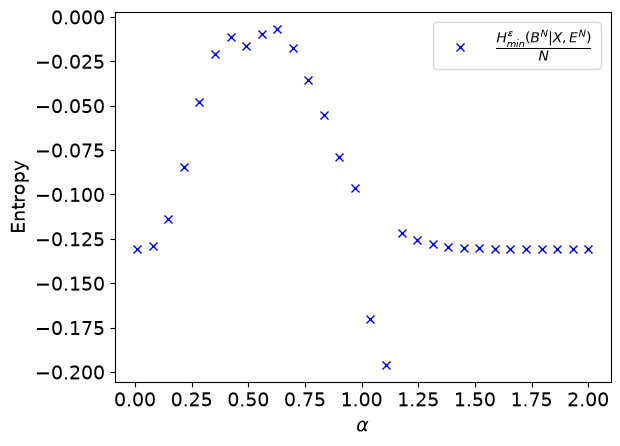

In [50]:
plt.figure()
plt.plot(alphas, res['vals'], 'bx', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "FiniteSizeBPSK3.pdf",
    bbox_inches="tight"
)

## Choosing d for BPSK with inconclusive

In [51]:
deltas = np.linspace(0,2,30)
res = {'shannon': [], 'hmin': [], 'deltas': []}

for d in deltas:
    alpha = 0.4
    delta, p = simulation.getProbas(alpha, 1, 0, '3', False, d)
    hmin = HminLower.getHmin(p, delta, 1/2, True)
    shannon = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)
    

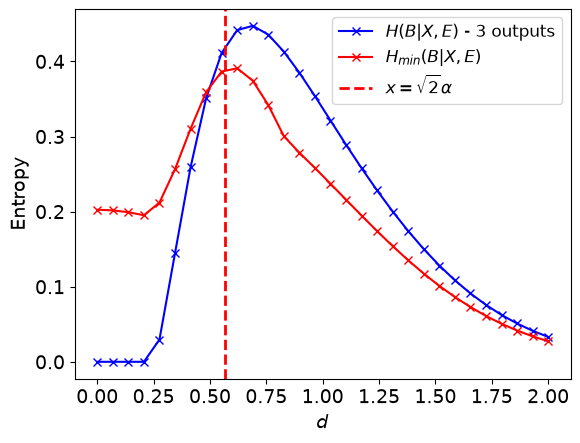

In [52]:
plt.figure()
plt.plot(deltas, res['shannon'], 'bx-', label=r'$H(B|X,E)$ - 3 outputs')
plt.plot(deltas, res['hmin'], 'rx-', label=r'$H_{min}(B|X,E)$')
plt.axvline(x=np.sqrt(2)*alpha, color='red', linestyle='--', linewidth=2, label=r'$x=\sqrt{2}\alpha$')
plt.xlabel(r'$d$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "DeltaBPSK.pdf",
    bbox_inches="tight"
)

In [53]:
import GraamBFF

# Quantum Eve without y

In [54]:
alphas = np.linspace(0,2,10) ### Z depends on y
Hs = []
for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '0') 
    Hs.append(GraamBFF.runSDP(p, delta, 1/2))

/opt/anaconda3/envs/qrngGVA/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/opt/anaconda3/envs/qrngGVA/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


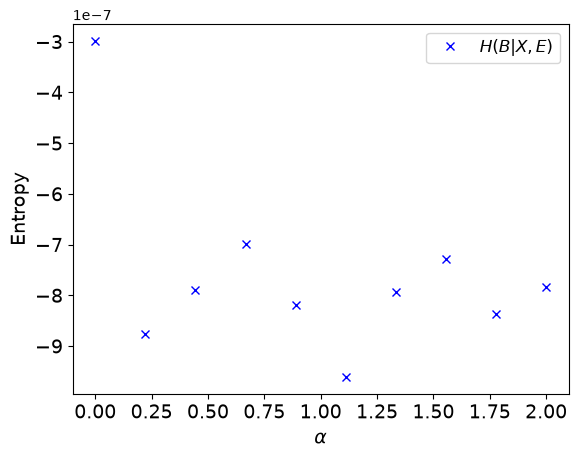

In [55]:
plt.figure()
plt.plot(alphas, Hs, 'bx', label=r'$H(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

In [56]:
import GraamBFF4

# Quantum Eve with y

In [57]:
alphas = np.linspace(0,2,20) ### Z depends on y
Hs = []
for alpha in alphas:
    delta = np.exp(-np.abs(alpha)**2 / 2)

    p = {0: {0: {0: 1, 1: 1-delta**2}, 1: {0: delta**2, 1: 0}}, 1: {0: {0: 0, 1: delta**2}, 1: {0: 1-delta**2, 1: 1}}}  
    Hs.append(GraamBFF4.runSDP(p, delta, 1/2))

SolverError: Solver 'MOSEK' failed. Try another solver, or solve with verbose=True for more information.

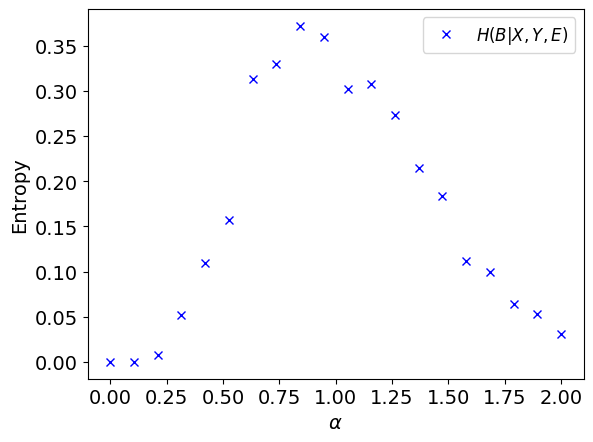

In [ ]:
plt.figure()
plt.plot(alphas, Hs, 'bx', label=r'$H(B|X,Y,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

In [ ]:
alphas = np.linspace(0,2,20) ### Z depends on y
Hs = []
eff=0.7
dc=1e-6
for alpha in alphas:
    delta = np.exp(-np.abs(alpha)**2 * eff / 2)

    p = {0: {0: {0: 1, 1: 1-delta**2}, 1: {0: delta**2, 1: 0}}, 1: {0: {0: 0, 1: delta**2}, 1: {0: 1-delta**2, 1: 1}}}  
    Hs.append(GraamBFF4.runSDP(p,  np.exp(-np.abs(alpha)**2 / 2), 1/2))

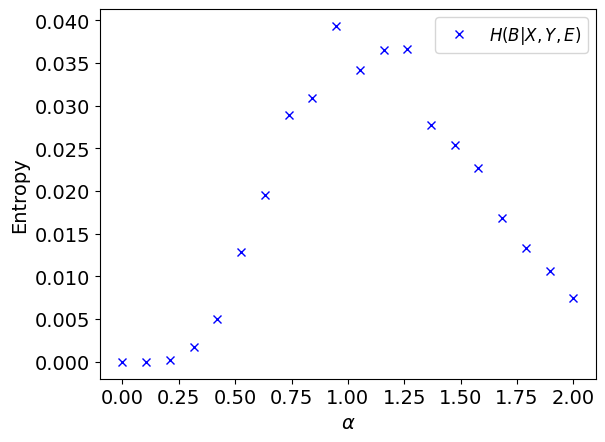

In [ ]:
plt.figure()
plt.plot(alphas, Hs, 'bx', label=r'$H(B|X,Y,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)

In [ ]:
alphas = np.linspace(0,2,10) ### Z depends on y
Hs = []
eff=0.2
for alpha in alphas:
    delta = np.exp(-np.abs(alpha)**2 * eff / 2)

    p = {0: {0: {0: 1, 1: 1-delta**2}, 1: {0: delta**2, 1: 0}}, 1: {0: {0: 0, 1: delta**2}, 1: {0: 1-delta**2, 1: 1}}}  
    Hs.append(GraamBFF4.runSDP(p, np.exp(-np.abs(alpha)**2 / 2), 1/2))

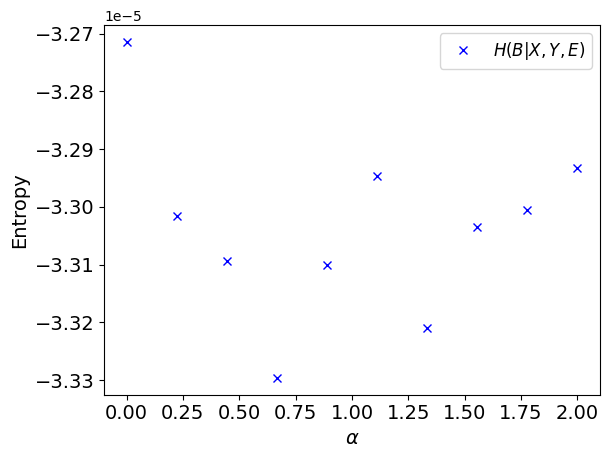

In [ ]:
plt.figure()
plt.plot(alphas, Hs, 'bx', label=r'$H(B|X,Y,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)